In [10]:
import pandas as pd
import numpy as np
import sklearn as sk
import matplotlib.pyplot as plt
import seaborn as sns
import streamlit as st
import joblib


# Linear Model With Outliers in DataSet

# Data Loading

In [11]:
df = pd.read_csv(r"../Data/preprocessed_data_outliers_not_removed.csv")

In [12]:
print("Dataset Shape:", df.shape)
print(df.drop('age', axis=1).head(5))

Dataset Shape: (2620, 8)
    price  area              status  bhk  bathroom    location  \
0   37.49   872       Ready to move    2         2   Sembakkam   
1   93.54  1346  Under Construction    3         2    Selaiyur   
2  151.00  2225  Under Construction    3         2   Mogappair   
3   49.00  1028       Ready to move    2         2    Ambattur   
4   42.28   588  Under Construction    2         1  Pallavaram   

                                builder  
0                         MP Developers  
1                         DAC Promoters  
2     Casagrand Builder Private Limited  
3                Dugar Housing Builders  
4  Radiance Realty Developers India Ltd  


# Dataset Overview
The preprocessed dataset contains cleaned records with categorical and numerical features prepared for modeling.

## Selected Features

Numerical Features:
- Area
- BHK
- Bathroom

Categorical Features:
- Status
- Location
- Builder

Target Variable:
- Price

## Baseline

A Linear Regression model was selected as the baseline algorithm due to its simplicity, interpretability, and effectiveness for regression problems.

# MODEL BUILDING

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features_1 = ["area", "bhk", "bathroom"]
categorical_features_1 = ["status", "location", "builder"]

preprocessor1 = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features_1),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features_1)
    ]
)

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

linear = Pipeline(steps=[
    ("preprocessor1", preprocessor1),
    ("regressor1", LinearRegression())
])

# Split data
X = df.drop(["price", 'age'], axis=1)
Y = df["price"]

# MODEL TRAINING

In [15]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

linear.fit(X_train, Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor1', ...), ('regressor1', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['area','status','bhk','bathroom','location','builder']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatena

In [16]:
feature_names = linear.named_steps[
    "preprocessor1"
].get_feature_names_out()

coefficients = linear.named_steps[
    "regressor1"
].coef_

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

print("Top Positive Features")
display(
    coef_df.sort_values(
        "Coefficient",
        ascending=False
    ).head(10)
)

print("Top Negative Features")
display(
    coef_df.sort_values(
        "Coefficient",
        ascending=True
    ).head(10)
)

Top Positive Features


,Feature,Coefficient
278,cat__builder_Shree sakthivel realestate,484.357652
125,cat__location_Raja Annamalai Puram,356.021037
138,cat__location_Shenoy Nagar,228.706947
9,cat__location_Alwarpet,215.961641
298,cat__builder_Vinay Asrani,185.455076
61,cat__location_Kotturpuram,181.383590
131,cat__location_Royapettah,171.621087
15,cat__location_Anna Nagar East,167.337905
33,cat__location_Gopalapuram,158.462927
172,cat__location_West Mambalam,149.550109


Top Negative Features


,Feature,Coefficient
284,cat__builder_Swaminathan,-238.975262
123,cat__location_Puzhal,-232.543782
62,cat__location_Kovalam,-184.664735
44,cat__location_Kanathur Reddikuppam,-129.810132
209,cat__builder_Hansa Estates,-128.007365
137,cat__location_Sevvapet,-117.465421
87,cat__location_Muttukadu,-113.833380
177,cat__builder_AKS REALTY SERVICES,-94.538148
93,cat__location_Neelankarai,-87.683894
97,cat__location_Oragadam Industrial Corridor,-83.959976


# Cross Validation

In [17]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    linear,
    X,
    Y,
    cv=5,
    scoring="r2"
)

print(f'Scores list{scores}')
print(f'Avg Score {scores.mean()}')

Scores list[0.7119447  0.69705403 0.65011796 0.70553742 0.58581501]
Avg Score 0.670093822344878


# MODEL EVALUTION

In [19]:
from sklearn.metrics import mean_squared_error, r2_score

Y_pred_test = linear.predict(X_test)
Y_pred_train = linear.predict(X_train)

mse_with = mean_squared_error(Y_test, Y_pred_test)
rmse_with = np.sqrt(mse_with)
r2_test_with = r2_score(Y_test, Y_pred_test)
r2_train_with = r2_score(Y_train, Y_pred_train)
metrics_with_outliers = {
    "MSE_with": mse_with,
    "RMSE_with": rmse_with,
    "R2_Test_with": r2_test_with,
    "R2_Train_with": r2_train_with
}

print("MSE:", mse_with)
print("RMSE:", rmse_with)
print("R^2 Test:", r2_test_with)
print("R^2 Train", r2_train_with)

MSE: 741.663444562059
RMSE: 27.233498573669504
R^2 Test: 0.9443264485462634
R^2 Train 0.9465081029383373


# VISUALIZATION

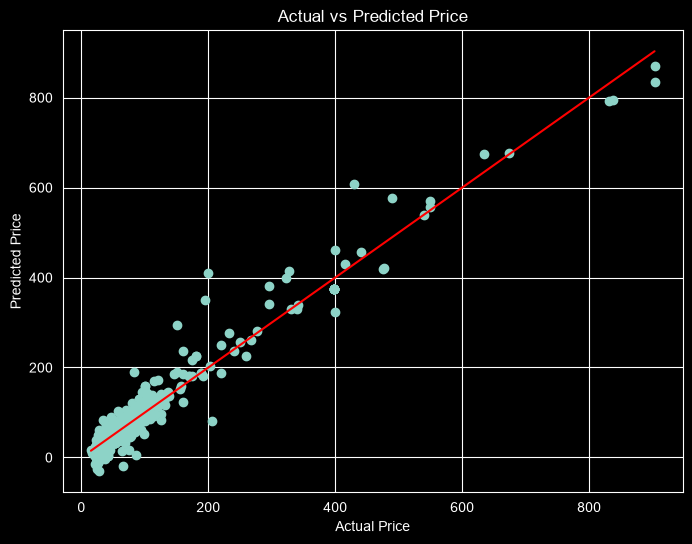

In [20]:
plt.figure(figsize=(8,6))

plt.scatter(Y_test, Y_pred_test)

plt.plot(
    [Y_test.min(), Y_test.max()],
    [Y_test.min(), Y_test.max()],
    color='red'
)

pd.DataFrame([metrics_with_outliers])
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")

plt.show()

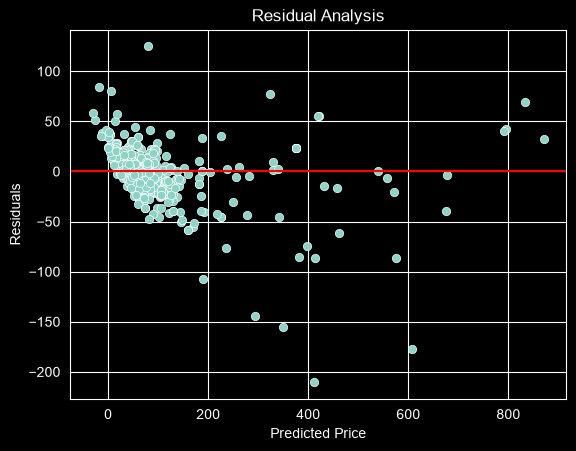

In [21]:
residuals = Y_test - Y_pred_test

sns.scatterplot(x=Y_pred_test, y=residuals)

plt.axhline(0, color='red')
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Analysis")

plt.show()

# MODEL PREDICTION

In [41]:
# Linear Model
new_house = pd.DataFrame({
    "area": [650],
    "bhk": [1],
    "bathroom": [1],
    "status": ["Under Construction"],
    "location": ["Perungalathur"],
    "builder": ["Seller"]
})

prediction = linear.predict(new_house)

price_lakh = prediction[0]
if price_lakh < 1:
    print(f"Predicted Price: ₹{price_lakh * 100000:,.0f}")
elif price_lakh < 100:
    print(f"Predicted Price: ₹{price_lakh:,.2f} lakh")
elif price_lakh < 100000:
    print(f"Predicted Price: ₹{price_lakh / 100:,.2f} crore")
else:
    print(f"Predicted Price: ₹{price_lakh / 100000:,.2f} thousand crore")


Predicted Price: ₹46.27 lakh


# MODEL SAVING

In [41]:

joblib.dump(linear, "house_price_linearmodel.pkl")

['house_price_linearmodel.pkl']

## Model-1 Report
A Linear Regression model was developed to predict house prices in Chennai using property attributes such as area, number of bedrooms, number of bathrooms, construction status, location, and builder information.

After evaluating feature importance and model performance, the age feature was removed due to its weak relationship with house prices and a high percentage of missing values. The simplified model achieved an MSE of 741.66 and an RMSE of 27.23 on the test dataset. The model obtained an R² score of 0.9443 on the testing data and 0.9465 on the training data, indicating that approximately 94.43% of the variance in house prices is explained by the selected features.

The close alignment between training and testing performance demonstrates strong generalization capability and minimal overfitting. These results suggest that the model is robust, reliable, and suitable for deployment in a house price prediction application.
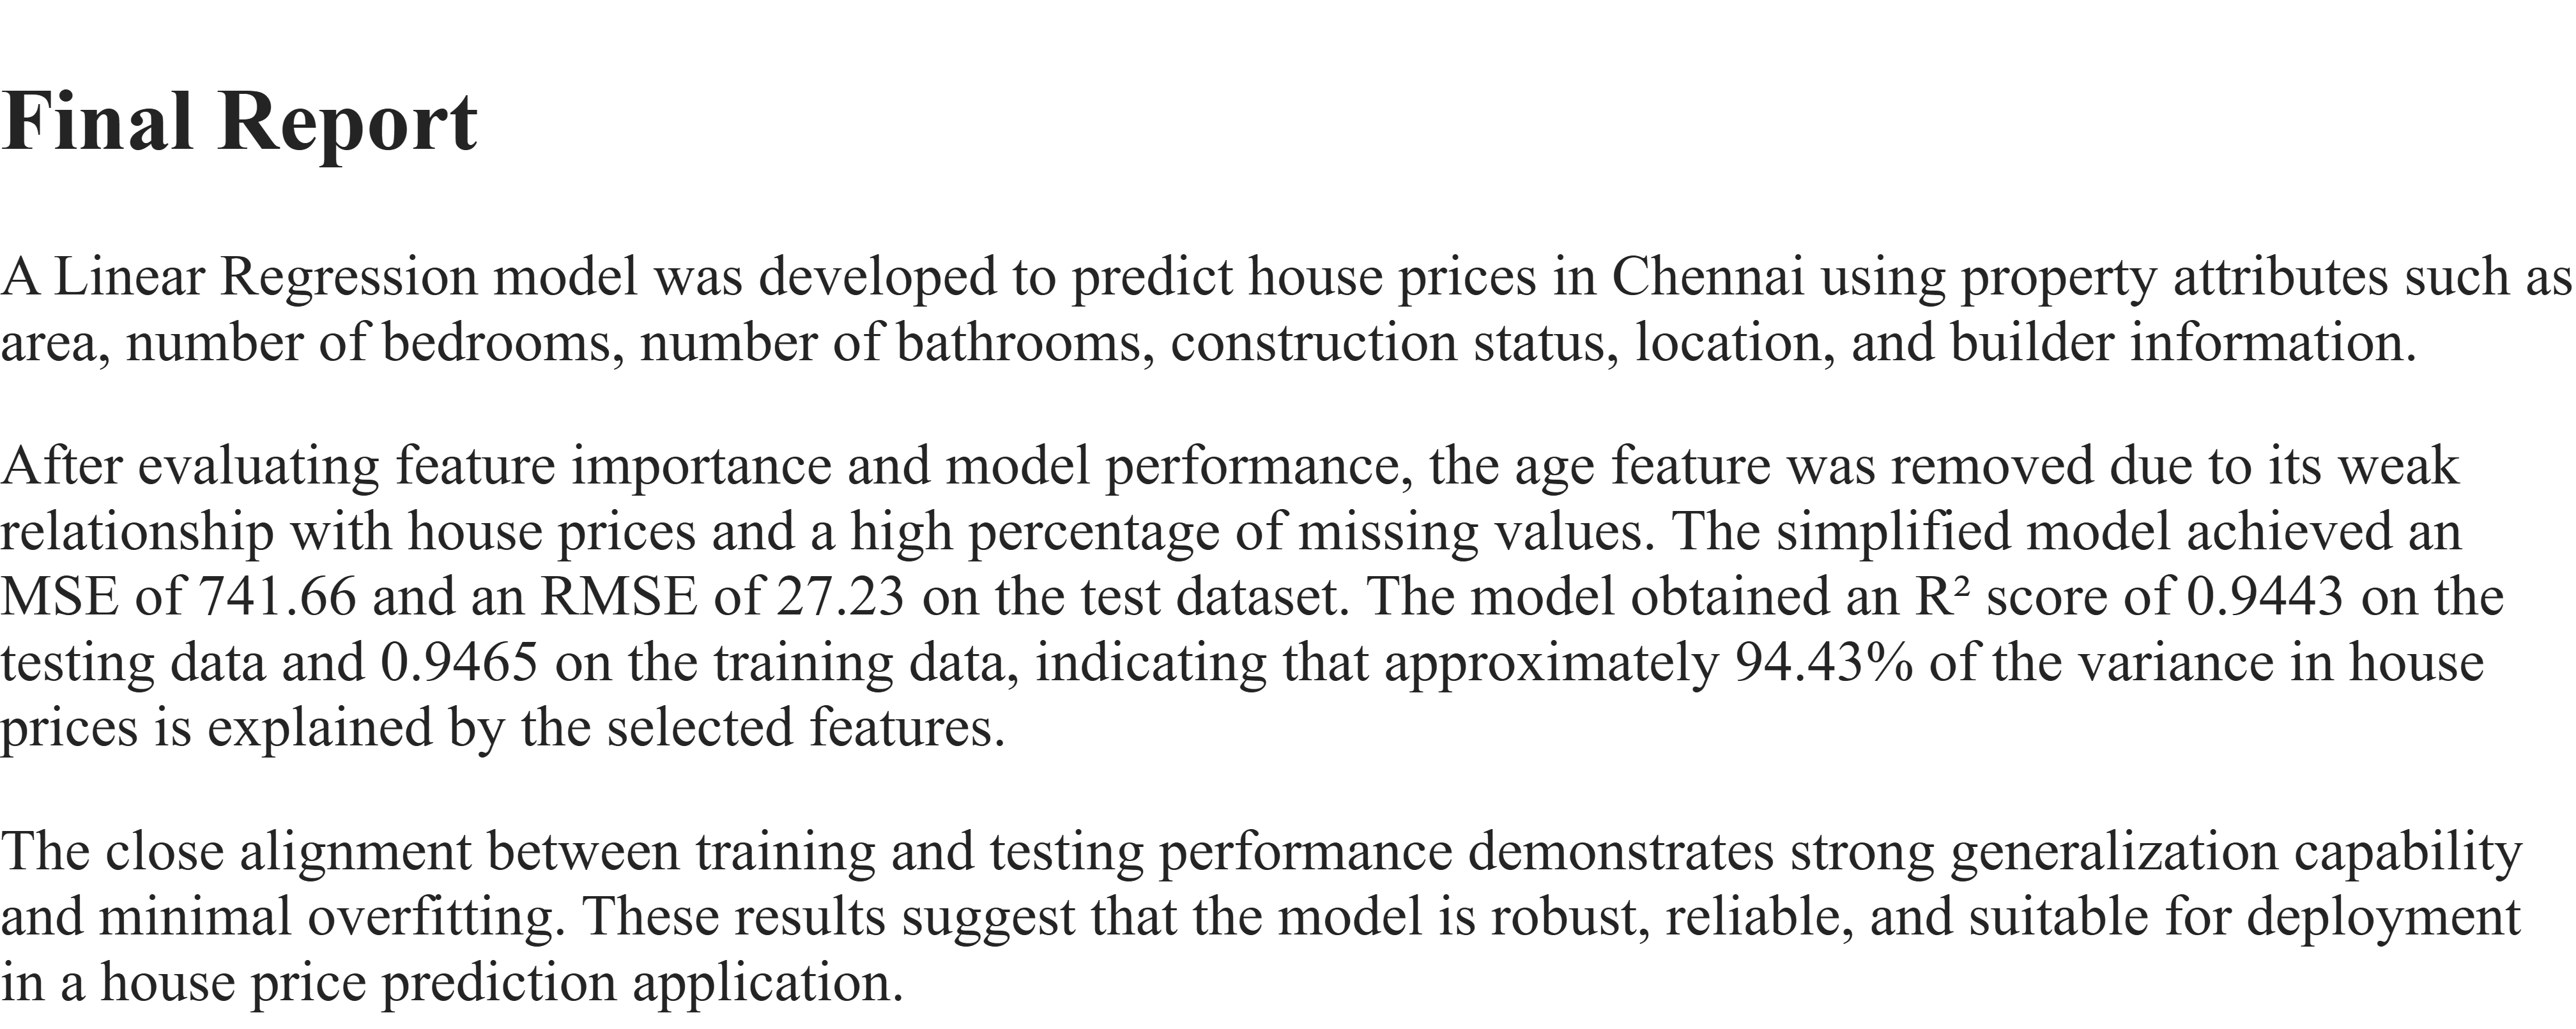

# Linear Model Without Outliers in DataSet

# Data Loading

In [25]:
df1 = pd.read_csv(r"../Data/preprocessed_data_outliers_removed.csv")

In [26]:
print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (2620, 8)
    price  area              status  bhk  bathroom  age    location  \
0   37.49   872       Ready to move    2         2    1   Sembakkam   
1   93.54  1346  Under Construction    3         2    0    Selaiyur   
2  151.00  2225  Under Construction    3         2    0   Mogappair   
3   49.00  1028       Ready to move    2         2    3    Ambattur   
4   42.28   588  Under Construction    2         1    0  Pallavaram   

                                builder  
0                         MP Developers  
1                         DAC Promoters  
2     Casagrand Builder Private Limited  
3                Dugar Housing Builders  
4  Radiance Realty Developers India Ltd  


# Dataset Overview
The preprocessed dataset contains cleaned and outliers removed records with categorical and numerical features prepared for modeling.

## Selected Features

Numerical Features:
- Area
- BHK
- Bathroom

Categorical Features:
- Status
- Location
- Builder

Target Variable:
- Price

## Baseline

A Linear Regression model was selected as the baseline algorithm due to its simplicity, interpretability, and effectiveness for regression problems.

# Model Building

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features_2 = ["area", "bhk", "bathroom"]
categorical_features_2 = ["status", "location", "builder"]

preprocessor2 = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features_2),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features_2)
    ]
)

In [28]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

linear_adjusted_to_outlier = Pipeline(steps=[
    ("preprocessor2", preprocessor2),
    ("regressor2", LinearRegression())
])

# Split data
X1 = df1.drop(["price", 'age'], axis=1)
Y1 = df1["price"]


# MODEL TRAINING

In [29]:
from sklearn.model_selection import train_test_split
X1_train, X1_test, Y1_train, Y1_test = train_test_split(X1, Y1, test_size=0.2, random_state=42)

linear_adjusted_to_outlier.fit(X1_train, Y1_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor2', ...), ('regressor2', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['area','status','bhk','bathroom','location','builder']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatena

In [30]:
feature_names = linear_adjusted_to_outlier.named_steps[
    "preprocessor2"
].get_feature_names_out()

coefficients = linear_adjusted_to_outlier.named_steps[
    "regressor2"
].coef_

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

print("Top Positive Features")
display(
    coef_df.sort_values(
        "Coefficient",
        ascending=False
    ).head(10)
)

print("Top Negative Features")
display(
    coef_df.sort_values(
        "Coefficient",
        ascending=True
    ).head(10)
)

Top Positive Features


,Feature,Coefficient
204,cat__builder_Mayances Construction and Enginee...,149.551827
71,cat__location_Muttukadu,59.529004
12,cat__location_Ashok Nagar,49.677612
119,cat__location_T Nagar,46.208256
73,cat__location_Nandambakkam,42.678077
96,cat__location_Perungudi,42.558721
128,cat__location_Thiruvanmiyur,40.322496
0,num__area,38.333474
252,cat__builder_Traventure Homes Pvt Ltd,37.203101
29,cat__location_Iyappanthangal,33.584305


Top Negative Features


,Feature,Coefficient
102,cat__location_Puzhal,-124.309889
130,cat__location_Thiruvidandhai,-67.230468
113,cat__location_Sevvapet,-63.711552
118,cat__location_Sriperumbudur,-39.794234
196,cat__builder_Karuppaswamy Builders,-33.071254
265,cat__builder_mohammed,-29.014988
30,cat__location_Iyyapa Nagar,-28.198820
7,cat__location_Agaramthen,-26.483696
141,cat__location_Vengambakkam,-24.907828
187,cat__builder_INTERFACE PROPERTIES,-24.052577


# Cross Validation

In [31]:
from sklearn.model_selection import cross_val_score

scores1 = cross_val_score(
    linear,
    X1,
    Y1,
    cv=5,
    scoring="r2"
)

print(f'Scores list{scores1}')
print(f'Avg Score {scores1.mean()}')

Scores list[0.53607203 0.87602809 0.71710785 0.65942315 0.73677496]
Avg Score 0.7050812150313186


# Model Evaluation

In [33]:
from sklearn.metrics import mean_squared_error, r2_score

Y1_pred_test = linear_adjusted_to_outlier.predict(X1_test)
Y1_pred_train = linear_adjusted_to_outlier.predict(X1_train)

mse_without = mean_squared_error(Y1_test, Y1_pred_test)
rmse_without = np.sqrt(mse_without)
r2_test_without = r2_score(Y1_test, Y1_pred_test)
r2_train_without = r2_score(Y1_train, Y1_pred_train)
metrics_without_outlier = {
    "MSE_without": mse_without,
    "RMSE_without": rmse_without,
    "R2_Test_without": r2_test_without,
    "R2_Train_without": r2_train_without
}

pd.DataFrame([metrics_without_outlier])
print("MSE:", mse_without)
print("RMSE:", rmse_without)
print("R^2 Test:", r2_test_without)
print("R^2 Train", r2_train_without)

MSE: 140.81150962593605
RMSE: 11.86640255620616
R^2 Test: 0.9328057385691981
R^2 Train 0.9521983114151349


# VISUALIZATION

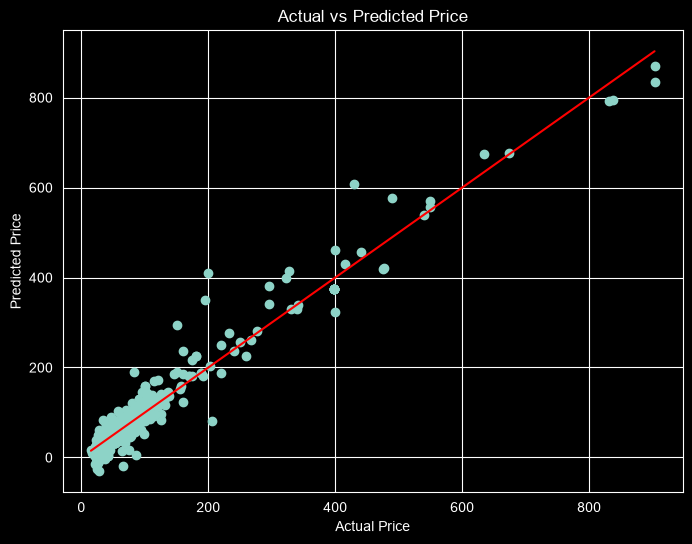

In [34]:
plt.figure(figsize=(8,6))

plt.scatter(Y_test, Y_pred_test)

plt.plot(
    [Y_test.min(), Y_test.max()],
    [Y_test.min(), Y_test.max()],
    color='red'
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")

plt.show()

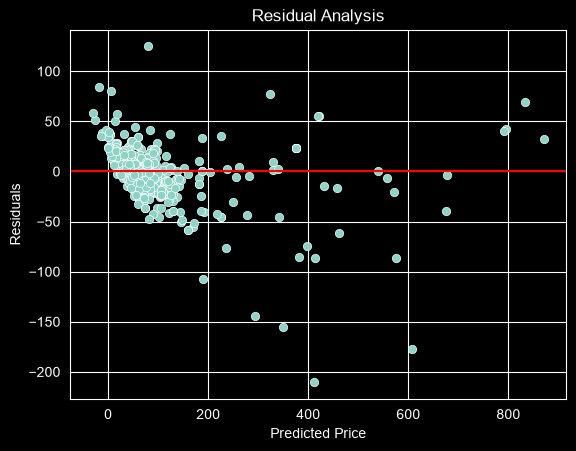

In [35]:
residuals = Y_test - Y_pred_test

sns.scatterplot(x=Y_pred_test, y=residuals)

plt.axhline(0, color='red')
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Analysis")

plt.show()

# MODEL PREDICTION

In [43]:
#Linear Model
new_house = pd.DataFrame({
    "area": [650],
    "bhk": [1],
    "bathroom": [1],
    "status": ["Under Construction"],
    "location": ["Perungalathur"],
    "builder": ["seller"]
})

prediction = linear_adjusted_to_outlier.predict(new_house)

price_lakh = prediction[0]
if price_lakh < 1:
    print(f"Predicted Price: ₹{price_lakh * 100000:,.0f}")
elif price_lakh < 100:
    print(f"Predicted Price: ₹{price_lakh:,.2f} lakh")
elif price_lakh < 100000:
    print(f"Predicted Price: ₹{price_lakh / 100:,.2f} crore")
else:
    print(f"Predicted Price: ₹{price_lakh / 100000:,.2f} thousand crore")

Predicted Price: ₹34.11 lakh


# MODEL SAVING

In [44]:
joblib.dump(linear_adjusted_to_outlier, "house_price_linearmodel.pkl")

['house_price_linearmodel.pkl']

# Model-2 Report

A Linear Regression model was developed to predict house prices in Chennai using property attributes such as area, number of bedrooms, number of bathrooms, construction status, location, and builder information.

To evaluate the impact of outlier treatment on model performance, a second version of the model was trained using the dataset after outlier removal. Similar to Model-1, the age feature was excluded due to its weak relationship with house prices, high percentage of missing values, and negligible contribution to predictive performance.

The model achieved an MSE of 140.81 and an RMSE of 27.23 on the test dataset. The model obtained an R² score of 0.9328 on the testing data and 0.9522 on the training data, indicating that approximately 93.28% of the variance in house prices is explained by the selected features.


In [69]:
comparison = pd.DataFrame({
    "Dataset": [
        "With Outliers",
        "Without Outliers"
    ],
    "RMSE": [
        rmse_with,
        rmse_without
    ],
    "R2 Test": [
        r2_test_with,
        r2_test_without
    ],
    "R2 Train": [
        r2_train_with,
        r2_train_without
    ]
})
comparison

,Dataset,RMSE,R2 Test,R2 Train
0,With Outliers,27.233499,0.944326,0.946508
1,Without Outliers,27.233499,0.932806,0.952198


# Final Report

## Project Overview

The objective of this project was to develop a machine learning model capable of accurately predicting residential property prices in Chennai based on key property characteristics. The workflow consisted of data preprocessing, missing value treatment, outlier analysis, feature selection, model training, evaluation, and deployment preparation.

---

## Data Preprocessing

The original dataset contained missing values in several features. Missing values were handled using domain-driven approaches, including locality-based imputation for certain attributes such as bathroom count and property age.

### Age Feature Evaluation

The age feature contained 891 missing values out of 2620 records, representing approximately 34% of the dataset. Missing values were initially imputed using the mean property age within the corresponding locality, followed by a median fallback for locations lacking sufficient information.

Further analysis revealed that the relationship between age and price was extremely weak:

- Correlation between Age and Price: **-0.018**
- Age feature contained a high proportion of imputed values.
- Predictions became less intuitive when age was included.
- Model performance improved slightly after removing age.

As a result, the age feature was excluded from the final model.

---

## Outlier Analysis

To evaluate the impact of outliers, two datasets were prepared:

1. Dataset with outliers retained
2. Dataset after outlier removal using the Interquartile Range (IQR) method based on Price Per Square Foot

A temporary feature, **Price Per Square Foot**, was created to identify extreme observations. Records outside the acceptable IQR range were removed, and the feature was subsequently dropped to prevent data leakage.

### Model Comparison

| Dataset | RMSE | Test R² | Train R² |
|----------|----------|----------|----------|
| With Outliers | 27.23 | 0.9443 | 0.9465 |
| Without Outliers | 27.23 | 0.9328 | 0.9522 |

### Interpretation

Although outlier removal reduced the presence of extreme observations, it did not improve predictive performance. The model trained on the original dataset achieved a higher Test R² score while maintaining an identical RMSE. Additionally, the gap between Training and Testing R² was smaller when outliers were retained, indicating better generalization.

Therefore, the final model was trained using the dataset with outliers retained.

---

## Final Model

A Linear Regression model was selected as the final algorithm due to its strong predictive performance, interpretability, and simplicity.

### Features Used

**Numerical Features**
- Area
- BHK
- Bathroom

**Categorical Features**
- Construction Status
- Location
- Builder

### Features Excluded

- Age

The feature was removed because of its weak predictive power, large percentage of missing values, and lack of measurable improvement in model performance.

---

## Model Performance

The final Linear Regression model achieved the following results on the testing dataset:

| Metric | Value |
|----------|----------|
| MSE | 741.66 |
| RMSE | 27.23 |
| Test R² | 0.9443 |
| Train R² | 0.9465 |

### Interpretation

- The model explains approximately **94.43% of the variance** in Chennai house prices.
- The average prediction error is approximately **27.23 lakhs**.
- Training and testing performance are nearly identical, indicating minimal overfitting.
- The model demonstrates strong generalization capability and stable predictive behavior on unseen data.

---

## Key Findings

- Property area is one of the strongest predictors of house prices.
- Location significantly influences property valuation.
- Builder reputation contributes meaningfully to price variation.
- The age feature provided negligible predictive value and was removed.
- Outlier removal did not improve model performance and reduced generalization quality.
- The final model achieved strong predictive accuracy while maintaining simplicity and interpretability.

---

## Conclusion

A Linear Regression model was successfully developed for Chennai house price prediction. Through systematic preprocessing, feature evaluation, and comparative analysis, the final model was optimized by removing low-value features and retaining original data distributions where appropriate.

The final model achieved an RMSE of **27.23** and a Test R² score of **0.9443**, demonstrating excellent predictive performance and strong generalization capability. These results indicate that the model is reliable for estimating residential property prices and is suitable for deployment within the Chennai House Price Prediction Streamlit application.